# Project 1: House Price Prediction

This notebook builds an end-to-end regression workflow that predicts the median house value of a California housing district from its location, size and demographic features.

**Workflow:** data loading, cleaning, exploratory analysis, preprocessing, feature engineering, model comparison, evaluation, model saving and prediction on new data.

## 1. Project Introduction

Accurate property valuation supports buyers, sellers, lenders and urban planners. The dataset describes block groups of the 1990 California census. Each row contains the location, the age and size of the housing stock, the local population, the median income and the median house value.

## 2. Problem Statement

Given the characteristics of a housing district, predict `median_house_value` (US dollars).

- **Type:** supervised learning, regression
- **Models compared:** Linear Regression, Random Forest, Gradient Boosting
- **Metrics:** MAE, RMSE and R². Model selection uses 5-fold cross-validation on the training set only. The test set is used once for the final evaluation.

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from features import (
    CATEGORICAL_COLUMNS,
    ENGINEERED_COLUMNS,
    MAX_PEOPLE_PER_HOUSEHOLD,
    MAX_ROOMS_PER_HOUSEHOLD,
    NUMERIC_COLUMNS,
    RAW_FEATURE_COLUMNS,
    RAW_NUMERIC_COLUMNS,
    TARGET_COLUMN,
    add_features,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 3. Dataset Loading

The dataset is read directly from a public GitHub raw URL. No manual download is needed.

In [2]:
DATA_URLS = [
    "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv",
]


def load_dataset(urls, **read_options):
    last_error = None
    for url in urls:
        try:
            return pd.read_csv(url, **read_options)
        except Exception as error:
            last_error = error
    raise RuntimeError(f"None of the dataset URLs could be loaded: {urls}") from last_error


housing = load_dataset(DATA_URLS)
print(f"Rows: {housing.shape[0]:,}  Columns: {housing.shape[1]}")
housing.head()

Rows: 20,640  Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 4. Data Overview

In [3]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [4]:
housing.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [5]:
missing_overview = pd.DataFrame(
    {
        "missing_values": housing.isna().sum(),
        "missing_percent": (housing.isna().mean() * 100).round(2),
    }
)
print(f"Duplicate rows: {housing.duplicated().sum()}")
missing_overview[missing_overview["missing_values"] > 0]

Duplicate rows: 0


,missing_values,missing_percent
total_bedrooms,207,1.0


## 5. Data Cleaning

Cleaning steps:

1. Remove duplicate rows.
2. Remove districts whose target value is censored at the dataset maximum. These values are an artificial cap, not real prices, and would bias the model.
3. Remove implausible districts with zero households or more than the allowed number of rooms or people per household.

Missing values in `total_bedrooms` are **not** filled here. They are imputed inside the modelling pipeline so the imputation statistics are learned from the training data only.

In [6]:
rows_initial = len(housing)
housing_clean = housing.drop_duplicates().copy()

censored_value = housing_clean[TARGET_COLUMN].max()
censored_rows = int((housing_clean[TARGET_COLUMN] == censored_value).sum())
housing_clean = housing_clean[housing_clean[TARGET_COLUMN] < censored_value]

housing_clean = housing_clean[housing_clean["households"] > 0]
rooms_per_household = housing_clean["total_rooms"] / housing_clean["households"]
people_per_household = housing_clean["population"] / housing_clean["households"]
plausible_rows = (rooms_per_household <= MAX_ROOMS_PER_HOUSEHOLD) & (people_per_household <= MAX_PEOPLE_PER_HOUSEHOLD)
housing_clean = housing_clean[plausible_rows].reset_index(drop=True)

print(f"Censored target value: {censored_value:,.0f} ({censored_rows} rows removed)")
print(f"Rows before cleaning: {rows_initial:,}")
print(f"Rows after cleaning:  {len(housing_clean):,}")
print(f"Remaining missing values:\n{housing_clean.isna().sum()[housing_clean.isna().sum() > 0]}")

Censored target value: 500,001 (965 rows removed)
Rows before cleaning: 20,640
Rows after cleaning:  19,598
Remaining missing values:
total_bedrooms    200
dtype: int64


## 6. Exploratory Data Analysis

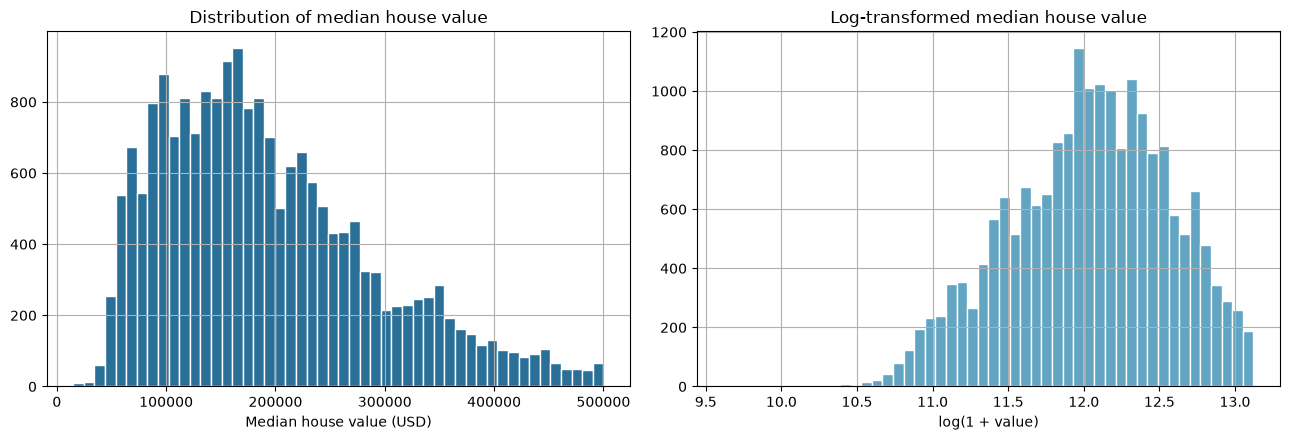

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(housing_clean[TARGET_COLUMN], bins=50, color="#2a6f97", edgecolor="white")
axes[0].set_title("Distribution of median house value")
axes[0].set_xlabel("Median house value (USD)")
axes[1].hist(np.log1p(housing_clean[TARGET_COLUMN]), bins=50, color="#61a5c2", edgecolor="white")
axes[1].set_title("Log-transformed median house value")
axes[1].set_xlabel("log(1 + value)")
plt.tight_layout()
plt.show()

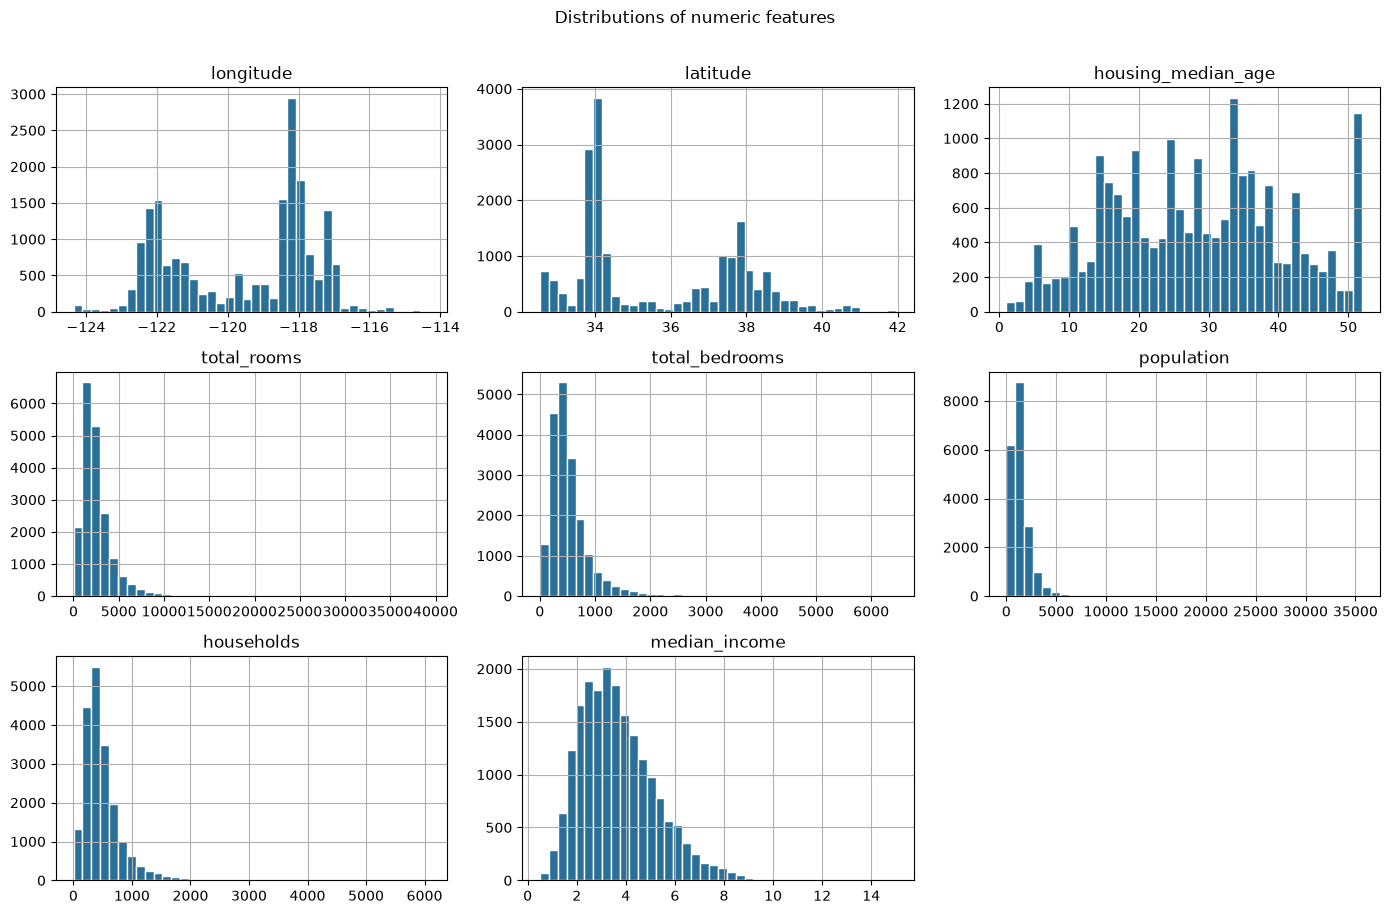

In [8]:
housing_clean[RAW_NUMERIC_COLUMNS].hist(bins=40, figsize=(14, 9), color="#2a6f97", edgecolor="white")
plt.suptitle("Distributions of numeric features", y=1.01)
plt.tight_layout()
plt.show()

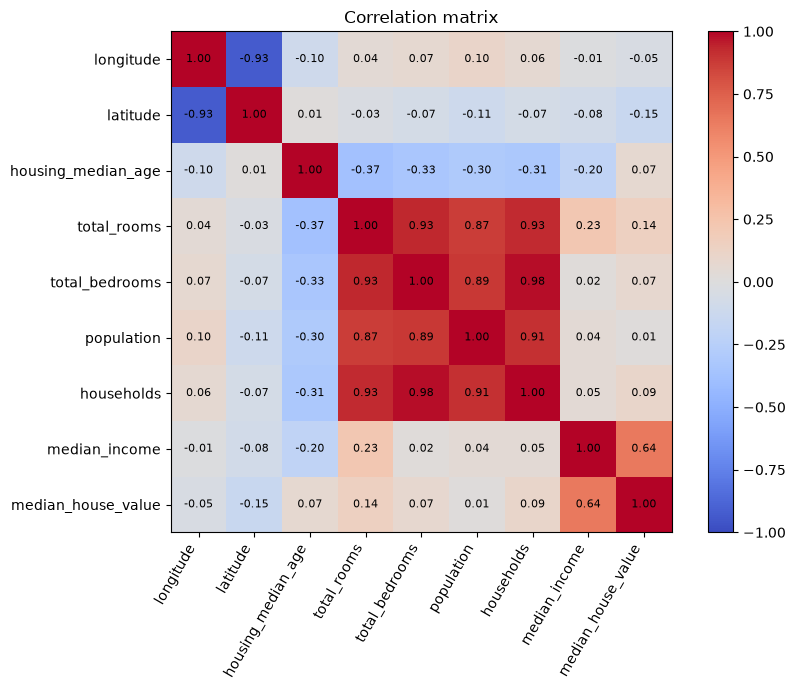

In [9]:
correlations = housing_clean[RAW_NUMERIC_COLUMNS + [TARGET_COLUMN]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)))
ax.set_yticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=60, ha="right")
ax.set_yticklabels(correlations.columns)
for row_index in range(len(correlations)):
    for column_index in range(len(correlations)):
        ax.text(column_index, row_index, f"{correlations.iloc[row_index, column_index]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(image)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

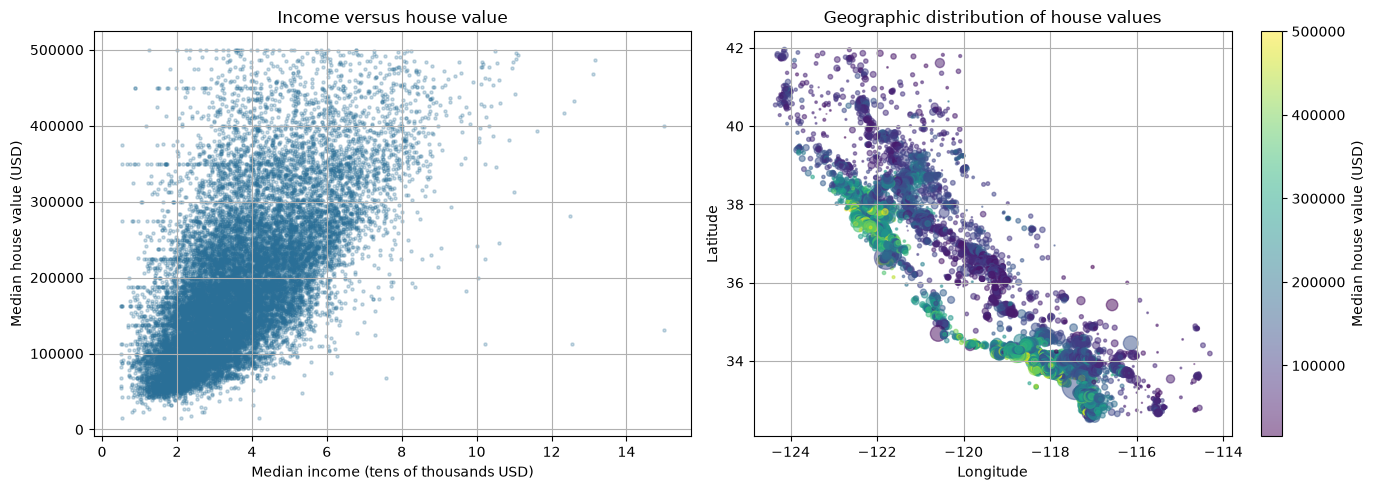

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(housing_clean["median_income"], housing_clean[TARGET_COLUMN], s=5, alpha=0.25, color="#2a6f97")
axes[0].set_xlabel("Median income (tens of thousands USD)")
axes[0].set_ylabel("Median house value (USD)")
axes[0].set_title("Income versus house value")
scatter = axes[1].scatter(
    housing_clean["longitude"],
    housing_clean["latitude"],
    c=housing_clean[TARGET_COLUMN],
    s=housing_clean["population"] / 100,
    cmap="viridis",
    alpha=0.5,
)
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title("Geographic distribution of house values")
fig.colorbar(scatter, ax=axes[1], label="Median house value (USD)")
plt.tight_layout()
plt.show()

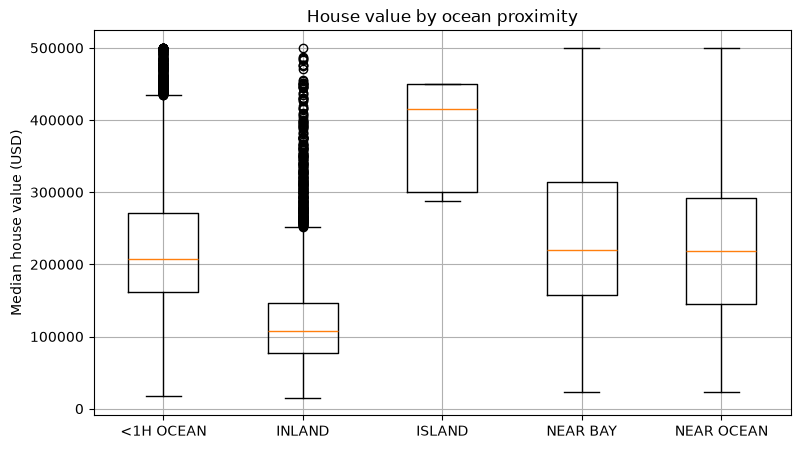

,count,mean,median
ocean_proximity,,,
<1H OCEAN,8603,223999.0,207600.0
INLAND,6450,122822.0,107900.0
ISLAND,5,380440.0,414700.0
NEAR BAY,2096,236926.0,219850.0
NEAR OCEAN,2444,227588.0,217950.0


In [11]:
category_names = sorted(housing_clean["ocean_proximity"].unique())
category_groups = [housing_clean.loc[housing_clean["ocean_proximity"] == name, TARGET_COLUMN].values for name in category_names]
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(category_groups)
ax.set_xticks(range(1, len(category_names) + 1))
ax.set_xticklabels(category_names)
ax.set_title("House value by ocean proximity")
ax.set_ylabel("Median house value (USD)")
plt.show()
housing_clean.groupby("ocean_proximity")[TARGET_COLUMN].agg(["count", "mean", "median"]).round(0)

## 7. Data Preprocessing

The data is split **before** any statistic is learned, which prevents data leakage. Imputation, scaling and one-hot encoding are all part of a scikit-learn `Pipeline`, so they are fitted on the training folds only and reused unchanged at prediction time.

In [12]:
feature_frame = housing_clean[RAW_FEATURE_COLUMNS]
target_series = housing_clean[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    feature_frame, target_series, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}  Test rows: {len(X_test):,}")


def build_pipeline(estimator):
    numeric_transformer = Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    )
    categorical_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    preprocessor = ColumnTransformer(
        [
            ("numeric", numeric_transformer, NUMERIC_COLUMNS),
            ("categorical", categorical_transformer, CATEGORICAL_COLUMNS),
        ]
    )
    return Pipeline(
        [
            ("features", FunctionTransformer(add_features)),
            ("preprocess", preprocessor),
            ("model", estimator),
        ]
    )

Training rows: 15,678  Test rows: 3,920


## 8. Feature Engineering

Three ratio features are derived from the raw counts because totals depend on the size of a district while ratios describe the living conditions inside it:

- `rooms_per_household`
- `bedrooms_per_room`
- `population_per_household`

The transformation is the function `add_features` in `features.py`. The same function is used inside the saved model, so the Streamlit app applies the identical logic.

In [13]:
engineered_preview = add_features(X_train)
engineered_correlation = (
    engineered_preview[ENGINEERED_COLUMNS]
    .assign(**{TARGET_COLUMN: y_train.values})
    .corr()[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
)
print("Correlation of engineered features with the target (training data):")
print(engineered_correlation.round(3))
engineered_preview[ENGINEERED_COLUMNS].head()

Correlation of engineered features with the target (training data):
rooms_per_household         0.207
bedrooms_per_room          -0.219
population_per_household   -0.227
Name: median_house_value, dtype: float64


,rooms_per_household,bedrooms_per_room,population_per_household
3434,7.599656,0.140629,3.427835
7402,3.523392,0.287967,2.152047
6541,4.635616,0.235225,3.095890
8709,9.769984,0.147437,2.915171
10221,3.087264,0.364400,3.136792


## 9. Model Training

Three models are trained with the same preprocessing pipeline. Each one is first scored with 5-fold cross-validation on the training set and then fitted on the full training set.

In [14]:
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=4, subsample=0.8, random_state=RANDOM_STATE
    ),
}

cross_validation = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cross_validation_rows = []
fitted_pipelines = {}

for model_name, estimator in candidate_models.items():
    pipeline = build_pipeline(estimator)
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cross_validation,
        scoring={"r2": "r2", "neg_rmse": "neg_root_mean_squared_error"},
    )
    cross_validation_rows.append(
        {
            "model": model_name,
            "cv_r2_mean": scores["test_r2"].mean(),
            "cv_r2_std": scores["test_r2"].std(),
            "cv_rmse_mean": -scores["test_neg_rmse"].mean(),
        }
    )
    fitted_pipelines[model_name] = pipeline.fit(X_train, y_train)
    print(f"Trained {model_name}")

cross_validation_table = pd.DataFrame(cross_validation_rows).set_index("model")
cross_validation_table.round(4)

Trained Linear Regression
Trained Random Forest
Trained Gradient Boosting


,cv_r2_mean,cv_r2_std,cv_rmse_mean
model,,,
Linear Regression,0.6323,0.0113,59002.3196
Random Forest,0.7852,0.0117,45086.2599
Gradient Boosting,0.8059,0.0082,42859.1705


## 10. Model Comparison

All models are evaluated on the untouched test set.

In [15]:
def regression_report(model_name, fitted_pipeline, features_frame, target_values):
    predictions = fitted_pipeline.predict(features_frame)
    return {
        "model": model_name,
        "MAE": mean_absolute_error(target_values, predictions),
        "RMSE": float(np.sqrt(mean_squared_error(target_values, predictions))),
        "R2": r2_score(target_values, predictions),
    }


test_table = pd.DataFrame(
    [regression_report(name, pipeline, X_test, y_test) for name, pipeline in fitted_pipelines.items()]
).set_index("model")
comparison_table = cross_validation_table.join(test_table)
comparison_table.round(4)

,cv_r2_mean,cv_r2_std,cv_rmse_mean,MAE,RMSE,R2
model,,,,,,
Linear Regression,0.6323,0.0113,59002.3196,43364.3781,59638.1899,0.6406
Random Forest,0.7852,0.0117,45086.2599,30072.4270,45469.8892,0.7911
Gradient Boosting,0.8059,0.0082,42859.1705,29635.3988,43770.8311,0.8064


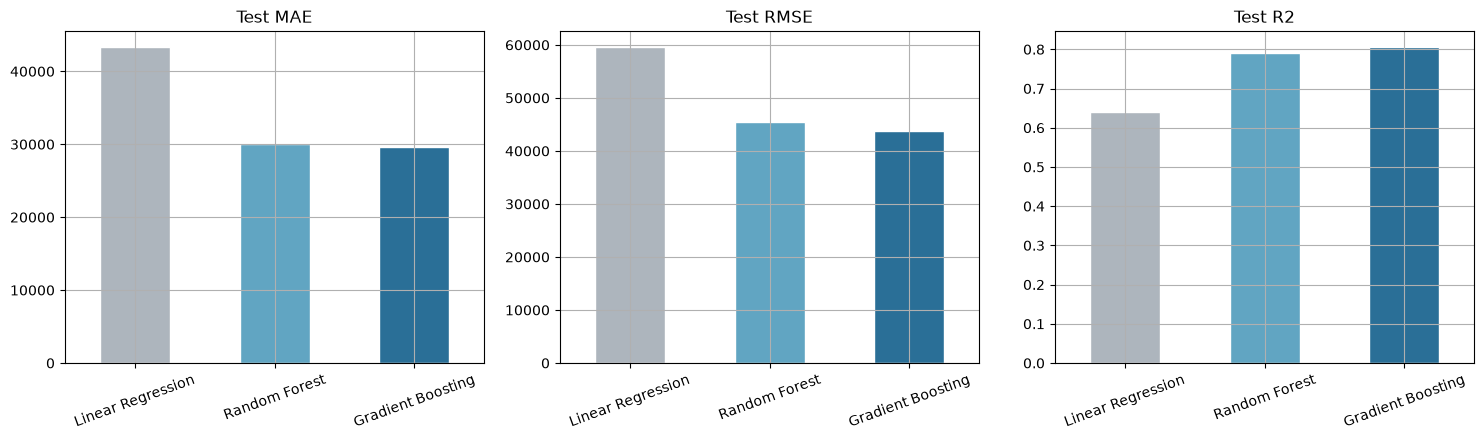

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    comparison_table[metric].plot(kind="bar", ax=axis, color=["#adb5bd", "#61a5c2", "#2a6f97"], edgecolor="white")
    axis.set_title(f"Test {metric}")
    axis.set_xlabel("")
    axis.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 11. Model Evaluation

The best model is inspected through predicted versus actual values, the residual distribution and permutation importance on the original input columns.

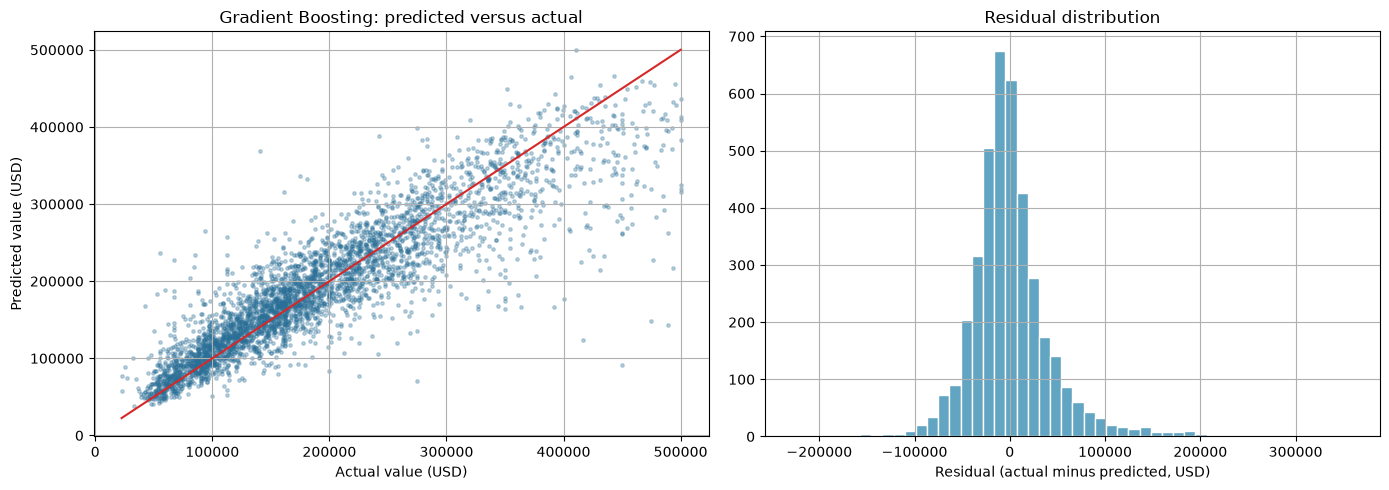

In [17]:
best_model_name = comparison_table["cv_r2_mean"].idxmax()
best_pipeline = fitted_pipelines[best_model_name]
test_predictions = best_pipeline.predict(X_test)
residuals = y_test - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, test_predictions, s=6, alpha=0.3, color="#2a6f97")
limits = [min(y_test.min(), test_predictions.min()), max(y_test.max(), test_predictions.max())]
axes[0].plot(limits, limits, color="#d62828", linewidth=1.5)
axes[0].set_xlabel("Actual value (USD)")
axes[0].set_ylabel("Predicted value (USD)")
axes[0].set_title(f"{best_model_name}: predicted versus actual")
axes[1].hist(residuals, bins=50, color="#61a5c2", edgecolor="white")
axes[1].set_xlabel("Residual (actual minus predicted, USD)")
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

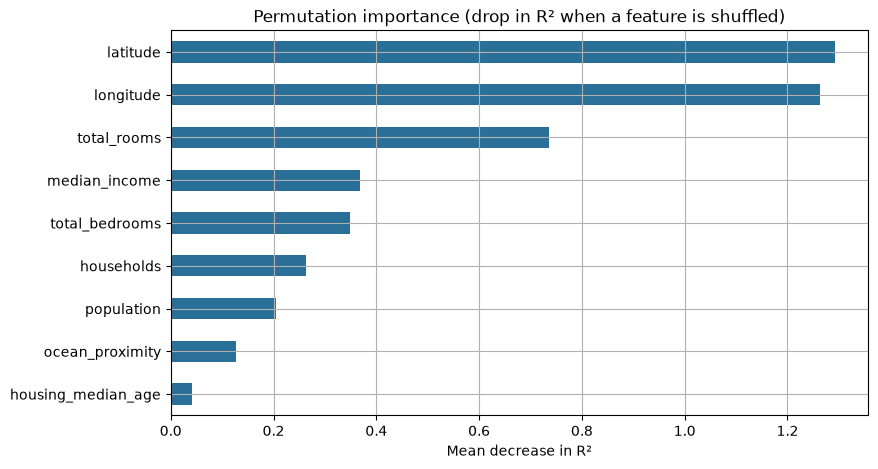

latitude              1.2925
longitude             1.2636
total_rooms           0.7368
median_income         0.3685
total_bedrooms        0.3484
households            0.2624
population            0.2054
ocean_proximity       0.1277
housing_median_age    0.0423
dtype: float64

In [18]:
importance_result = permutation_importance(
    best_pipeline, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1
)
feature_importance = (
    pd.Series(importance_result.importances_mean, index=X_test.columns)
    .sort_values(ascending=False)
)
feature_importance.sort_values().plot(kind="barh", color="#2a6f97", figsize=(9, 5))
plt.title("Permutation importance (drop in R² when a feature is shuffled)")
plt.xlabel("Mean decrease in R²")
plt.show()
feature_importance.round(4)

## 12. Best Model Selection

The model with the highest mean cross-validated R² on the training data is selected. Choosing with cross-validation instead of the test set keeps the test score an honest estimate of future performance.

In [19]:
best_test_metrics = regression_report(best_model_name, best_pipeline, X_test, y_test)
print(f"Selected model: {best_model_name}")
print(f"Test MAE:  {best_test_metrics['MAE']:,.0f} USD")
print(f"Test RMSE: {best_test_metrics['RMSE']:,.0f} USD")
print(f"Test R²:   {best_test_metrics['R2']:.4f}")

Selected model: Gradient Boosting
Test MAE:  29,635 USD
Test RMSE: 43,771 USD
Test R²:   0.8064


## 13. Model Saving

The complete pipeline (feature engineering, preprocessing and model) is saved as `model.pkl`. The file `metadata.json` stores the input ranges, categories, comparison table and feature importances used by the Streamlit app.

In [20]:
def json_default(value):
    return value.item() if hasattr(value, "item") else str(value)


numeric_ranges = {
    column: {
        "min": float(feature_frame[column].min()),
        "max": float(feature_frame[column].max()),
        "median": float(feature_frame[column].median()),
    }
    for column in RAW_NUMERIC_COLUMNS
}

metadata = {
    "project": "House Price Prediction",
    "target": TARGET_COLUMN,
    "best_model": best_model_name,
    "numeric_ranges": numeric_ranges,
    "categories": {column: sorted(feature_frame[column].unique().tolist()) for column in CATEGORICAL_COLUMNS},
    "test_metrics": best_test_metrics,
    "model_comparison": comparison_table.reset_index().to_dict(orient="records"),
    "feature_importance": feature_importance.to_dict(),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}

joblib.dump(best_pipeline, "model.pkl")
with open("metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, default=json_default)
print("Saved model.pkl and metadata.json")

Saved model.pkl and metadata.json


## 14. Prediction on New Data

The saved model is loaded from disk and used on new districts that were typed in by hand. A missing `total_bedrooms` value is handled by the imputer inside the pipeline.

In [21]:
loaded_model = joblib.load("model.pkl")

new_districts = pd.DataFrame(
    [
        {
            "longitude": -122.25,
            "latitude": 37.85,
            "housing_median_age": 30,
            "total_rooms": 2200,
            "total_bedrooms": 450,
            "population": 1100,
            "households": 420,
            "median_income": 5.2,
            "ocean_proximity": "NEAR BAY",
        },
        {
            "longitude": -118.30,
            "latitude": 34.05,
            "housing_median_age": 15,
            "total_rooms": 3500,
            "total_bedrooms": np.nan,
            "population": 2100,
            "households": 700,
            "median_income": 3.1,
            "ocean_proximity": "<1H OCEAN",
        },
        {
            "longitude": -121.40,
            "latitude": 39.10,
            "housing_median_age": 42,
            "total_rooms": 1500,
            "total_bedrooms": 320,
            "population": 800,
            "households": 300,
            "median_income": 2.0,
            "ocean_proximity": "INLAND",
        },
    ]
)[RAW_FEATURE_COLUMNS]

new_districts["predicted_median_house_value"] = loaded_model.predict(new_districts).round(0)
consistency_check = np.allclose(loaded_model.predict(X_test.head(50)), best_pipeline.predict(X_test.head(50)))
print(f"Loaded model matches the in-memory model: {consistency_check}")
new_districts

Loaded model matches the in-memory model: True


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,predicted_median_house_value
0,-122.25,37.85,30,2200,450.0,1100,420,5.2,NEAR BAY,253478.0
1,-118.30,34.05,15,3500,NaN,2100,700,3.1,<1H OCEAN,221526.0
2,-121.40,39.10,42,1500,320.0,800,300,2.0,INLAND,62607.0


## 15. Final Conclusion

In [22]:
ranked_features = ", ".join(feature_importance.head(3).index)
print(f"Best model by cross-validated R²: {best_model_name}")
print(f"Test R²: {best_test_metrics['R2']:.3f}  |  Test MAE: {best_test_metrics['MAE']:,.0f} USD  |  Test RMSE: {best_test_metrics['RMSE']:,.0f} USD")
print(f"Most influential features: {ranked_features}")
print()
print("Model ranking on the test set (R²):")
print(test_table["R2"].sort_values(ascending=False).round(4).to_string())

Best model by cross-validated R²: Gradient Boosting
Test R²: 0.806  |  Test MAE: 29,635 USD  |  Test RMSE: 43,771 USD
Most influential features: latitude, longitude, total_rooms

Model ranking on the test set (R²):
model
Gradient Boosting    0.8064
Random Forest        0.7911
Linear Regression    0.6406


**Summary of the approach**

- The pipeline compares a linear baseline against two tree ensembles. Tree ensembles can capture non-linear effects such as the interaction between location and income, which a linear model cannot.
- Rows with a censored target value were removed so that the model learns real prices.
- All preprocessing statistics are learned on training data only, and the model file contains the whole pipeline, so the app cannot drift from the training logic.

**Limitations and next steps**

- The data is from the 1990 census, so the predictions illustrate the method and are not a current market valuation.
- The target is a district-level median, not the price of an individual house.
- Possible improvements: hyperparameter search, geographic features such as distance to major cities, and gradient boosting libraries such as XGBoost or LightGBM.